In [22]:
import glob
import os
import time
import warnings

import cv2
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from skimage.feature import graycomatrix, graycoprops
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

In [23]:
warnings.filterwarnings("ignore")

In [24]:
DATASET_DIR = "datasets"
IMG_SIZE = (256, 256)
LEVELS = 64
DISTANCE = [1, 2, 3]
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

In [25]:
records = []

for dataset in os.listdir(DATASET_DIR):
    dataset_path = os.path.join(DATASET_DIR, dataset)
    if not os.path.isdir(dataset_path):
        continue

    img_files = []
    for extension in ("*.png", "*.jpg", "*.jpeg"):
        img_files.extend(glob.glob(os.path.join(dataset_path, extension)))

    for img_file in img_files:
        img = cv2.imread(img_file, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Gagal membaca gambar: {img_file}")

        img_resized = cv2.resize(img, IMG_SIZE)
        img_quantized = (img_resized.astype(np.uint16) * LEVELS // 256).astype(np.uint8)

        glcm = graycomatrix(
            img_quantized,
            distances=DISTANCE,
            angles=ANGLES,
            levels=LEVELS,
            symmetric=True,
            normed=True,
        )

        record = {"dataset": dataset, "image": img_file}
        for prop in PROPS:
            values = graycoprops(glcm, prop)
            for distance_idx, distance in enumerate(DISTANCE):
                for angle_idx, angle in enumerate(ANGLES):
                    column = f"{prop}_d{distance}_a{angle:.4f}"
                    record[column] = values[distance_idx, angle_idx]
        records.append(record)

df = pd.DataFrame.from_records(records)
if df.empty:
    raise ValueError(f"Tidak ada gambar yang ditemukan di {DATASET_DIR}")

df.to_csv("glcm_features.csv", index=False)

print(df.shape)
print(df["dataset"].value_counts())


(2303, 74)
dataset
E230199    77
E230209    60
E230050    60
E230068    59
E230109    57
E230156    56
E230002    56
E230091    55
E230171    54
E230059    53
E230194    53
E230083    52
E230052    52
E230011    52
E230187    52
E230188    52
E230111    52
E230099    52
E230046    52
E230086    51
E230146    51
E230117    51
E230151    51
E230225    51
E230018    51
E230031    51
E230144    51
E230110    50
E230028    50
E230067    50
E230125    50
E230005    50
E230094    50
E230020    50
E230066    50
E230034    50
E230017    50
E230155    50
E230120    50
E230076    50
E230119    50
E230116    50
E210077    47
E230108    42
Name: count, dtype: int64


In [26]:
df = pd.read_csv("glcm_features.csv")

In [27]:
df.shape
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 2303 entries, 0 to 2302
Data columns (total 74 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dataset                   2303 non-null   str    
 1   image                     2303 non-null   str    
 2   contrast_d1_a0.0000       2303 non-null   float64
 3   contrast_d1_a0.7854       2303 non-null   float64
 4   contrast_d1_a1.5708       2303 non-null   float64
 5   contrast_d1_a2.3562       2303 non-null   float64
 6   contrast_d2_a0.0000       2303 non-null   float64
 7   contrast_d2_a0.7854       2303 non-null   float64
 8   contrast_d2_a1.5708       2303 non-null   float64
 9   contrast_d2_a2.3562       2303 non-null   float64
 10  contrast_d3_a0.0000       2303 non-null   float64
 11  contrast_d3_a0.7854       2303 non-null   float64
 12  contrast_d3_a1.5708       2303 non-null   float64
 13  contrast_d3_a2.3562       2303 non-null   float64
 14  dissimilarity_d1_a0

dataset                    str
image                      str
contrast_d1_a0.0000    float64
contrast_d1_a0.7854    float64
contrast_d1_a1.5708    float64
                        ...   
ASM_d2_a2.3562         float64
ASM_d3_a0.0000         float64
ASM_d3_a0.7854         float64
ASM_d3_a1.5708         float64
ASM_d3_a2.3562         float64
Length: 74, dtype: object

In [28]:
count_imbalance = df["dataset"].value_counts()
print(count_imbalance)

dataset
E230199    77
E230209    60
E230050    60
E230068    59
E230109    57
E230156    56
E230002    56
E230091    55
E230171    54
E230059    53
E230194    53
E230083    52
E230052    52
E230011    52
E230187    52
E230188    52
E230111    52
E230099    52
E230046    52
E230086    51
E230146    51
E230117    51
E230151    51
E230225    51
E230018    51
E230031    51
E230144    51
E230110    50
E230028    50
E230067    50
E230125    50
E230005    50
E230094    50
E230020    50
E230066    50
E230034    50
E230017    50
E230155    50
E230120    50
E230076    50
E230119    50
E230116    50
E210077    47
E230108    42
Name: count, dtype: int64


In [29]:
encoder = LabelEncoder()
y = encoder.fit_transform(df["dataset"])

In [30]:
X = df.drop(columns=["dataset", "image"])
y = encoder.fit_transform(df["dataset"])

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [33]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

In [34]:
PARAMS_SVM = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf", "poly"],
    "gamma": ["scale", "auto"],
    "class_weight": [None, "balanced"],
}

PARAM_XGB = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0, 0.1, 0.2],
    "reg_alpha": [0, 0.1, 0.5],
    "reg_lambda": [1, 1.5, 2],
}

PARAM_LGBM = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "num_leaves": [31, 50, 100],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "reg_alpha": [0, 0.1, 0.5],
    "reg_lambda": [1, 1.5, 2],
}

In [35]:
models = {
    "SVM": (SVC(), PARAMS_SVM),
    "XGB": (xgb.XGBClassifier(verbosity=0), PARAM_XGB),
    "LGBM": (lgb.LGBMClassifier(verbosity=-1), PARAM_LGBM),
}

In [36]:
results = {}

for model_name, (model, params) in models.items():
    model_start_time = time.perf_counter()
    grid_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=10,
        scoring="accuracy",
        cv=cv,
        verbose=0,
        n_jobs=1,
        random_state=42,
    )
    grid_search.fit(X_scaled, y_train)
    training_time = time.perf_counter() - model_start_time
    best_model = grid_search.best_estimator_
    best_params = grid_search.best_params_
    best_score = grid_search.best_score_

    results[model_name] = {
        "best_model": best_model,
        "best_params": best_params,
        "best_score": best_score,
        "training_time_seconds": training_time,
    }


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Waktu training + pencarian (detik)
Model,,,,,
SVM,0.8395,0.8530,0.8408,0.8382,4.92
XGB,0.7137,0.7243,0.7101,0.7066,524.16
LGBM,0.6876,0.6971,0.6843,0.6788,95.15


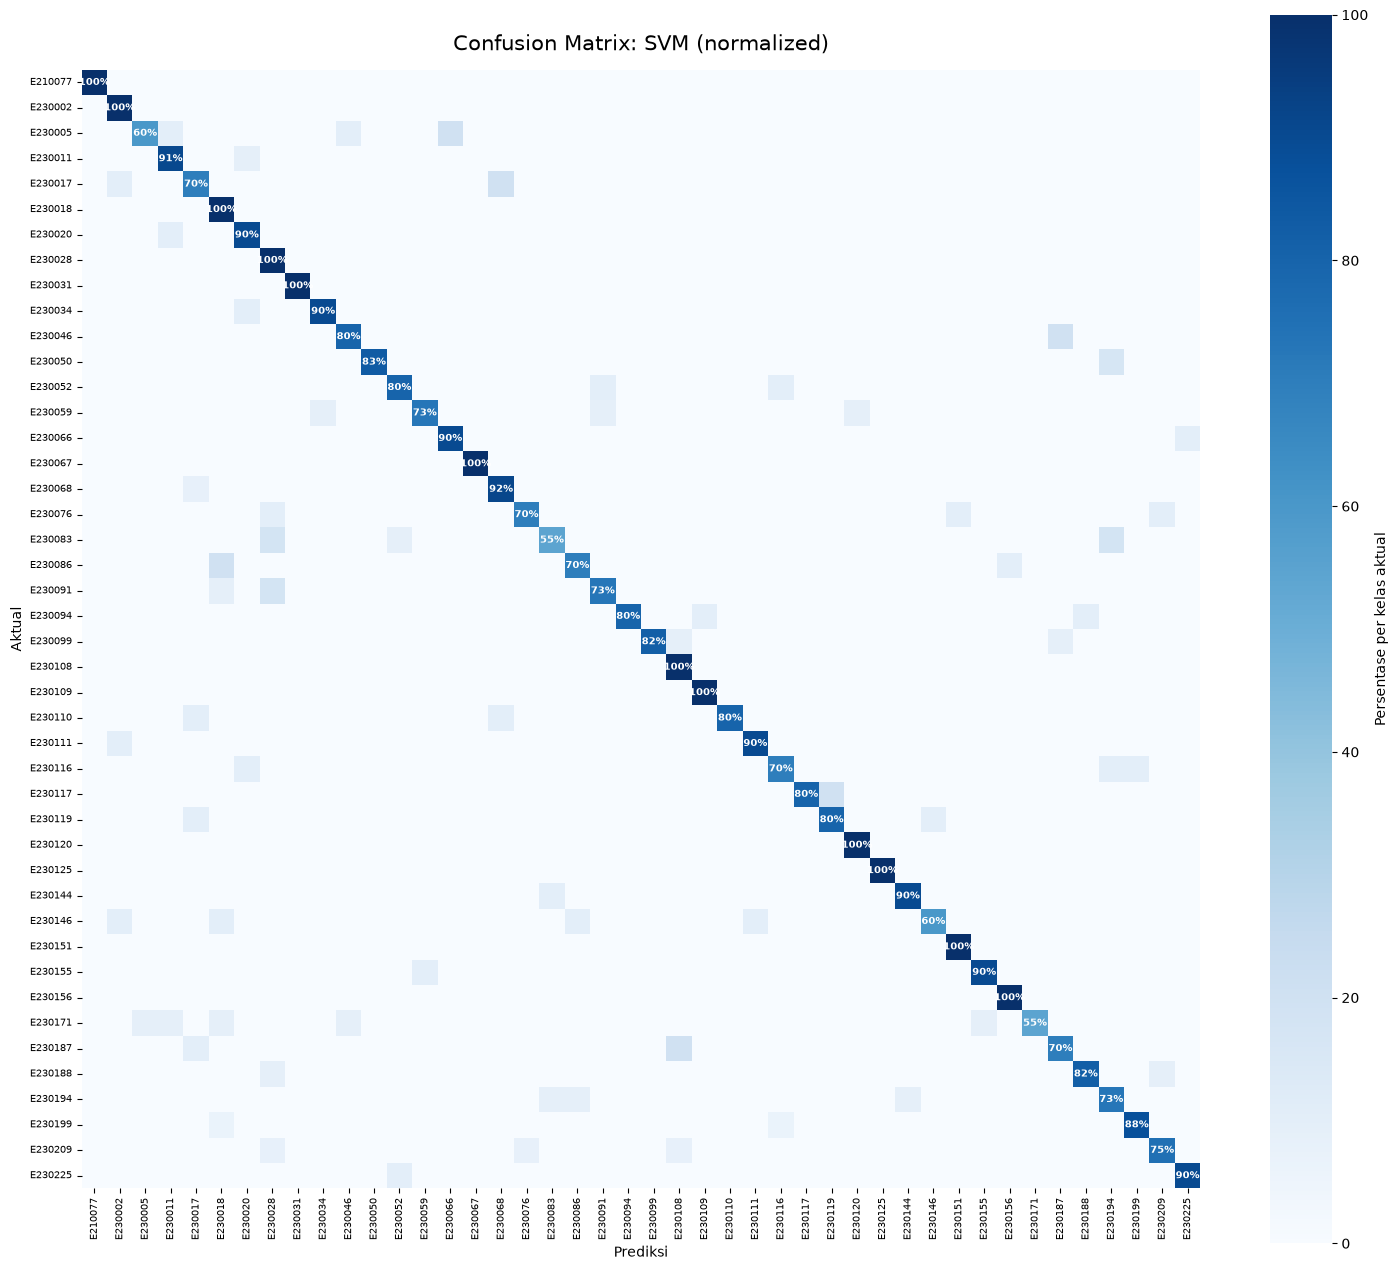

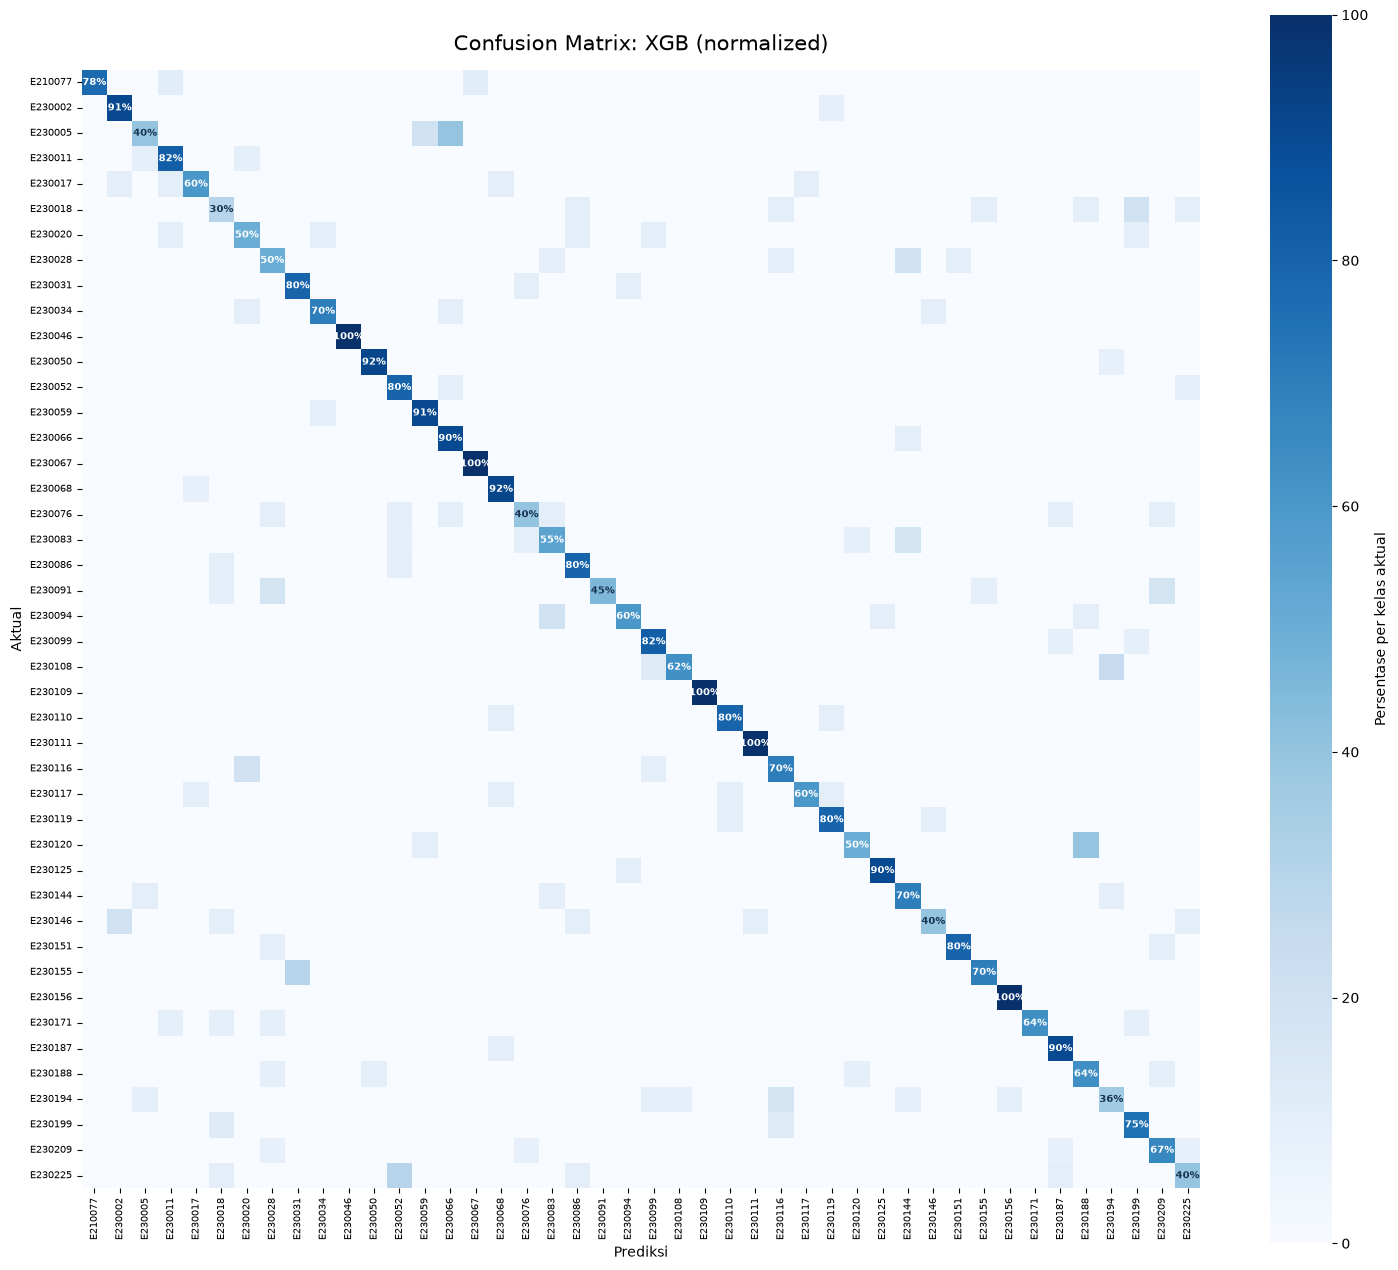

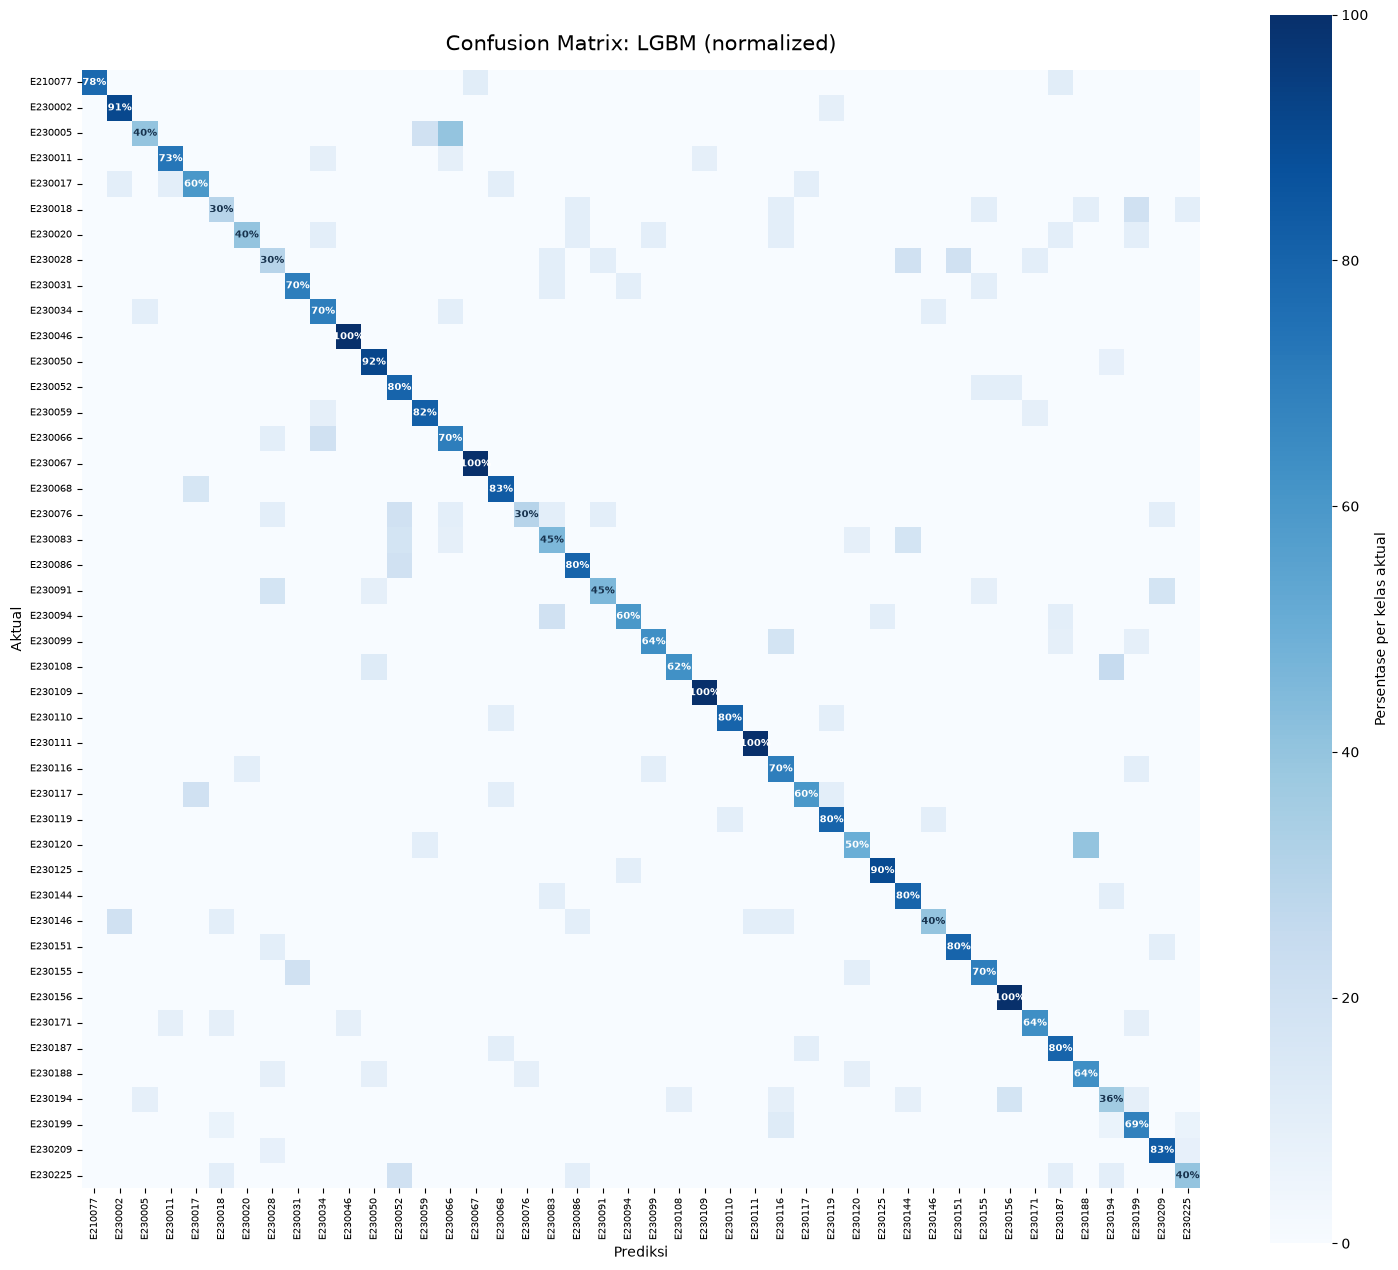

In [37]:
X_test_scaled = scaler.transform(X_test)
evaluation_rows = []

for model_name, result in results.items():
    y_pred = result["best_model"].predict(X_test_scaled)
    evaluation_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision (macro)": precision_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Recall (macro)": recall_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "F1-score (macro)": f1_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Waktu training + pencarian (detik)": result["training_time_seconds"],
        }
    )

comparison = pd.DataFrame(evaluation_rows).set_index("Model")
display(
    comparison.round(
        {
            "Accuracy": 4,
            "Precision (macro)": 4,
            "Recall (macro)": 4,
            "F1-score (macro)": 4,
            "Waktu training + pencarian (detik)": 2,
        }
    )
)

for model_name, result in results.items():
    y_pred = result["best_model"].predict(X_test_scaled)
    matrix = confusion_matrix(y_test, y_pred, labels=np.arange(len(encoder.classes_)))
    row_totals = matrix.sum(axis=1, keepdims=True)
    matrix_pct = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix, dtype=float),
        where=row_totals != 0,
    ) * 100

    fig, ax = plt.subplots(figsize=(15, 13))
    sns.heatmap(
        matrix_pct,
        cmap="Blues",
        vmin=0,
        vmax=100,
        square=True,
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_,
        cbar_kws={
            "label": "Persentase per kelas aktual",
            "ticks": [0, 20, 40, 60, 80, 100],
        },
        ax=ax,
    )
    for class_index, recall in enumerate(np.diag(matrix_pct)):
        text_color = "white" if recall >= 50 else "#17324d"
        ax.text(
            class_index + 0.5,
            class_index + 0.5,
            f"{recall:.0f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=7,
            fontweight="bold",
        )
    ax.set_title(f"Confusion Matrix: {model_name} (normalized)", fontsize=15, pad=14)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.tick_params(axis="y", labelrotation=0, labelsize=7)

    fig.tight_layout()
    plt.show()